# Step 6. Does fine-tuning the page reader help?

**The question.** Step 4's reader finds only 43% of the question numbers on answer sheets. Step 5 built 1,012
exam-like training pages. If the reader is fine-tuned on them, does it find more question numbers on the
development set, without reading the text worse?

**LoRA, on a laptop.** Qwen3-VL-2B has 2.1 billion parameters; training all of them would need far more memory
than a laptop has. LoRA leaves the model's weights as they are and trains small low-rank matrices added to the
language model's attention and MLP layers: 17.4 million parameters, 0.8% of the model. The image encoder is not
touched: on the development set the errors are in what is written down, not in what is seen.

    Part 1  Data          each page becomes the reader's prompt plus the text it should write; only the
                          answer's tokens are trained on
    Part 2  Training      AdamW, warm-up then cosine decay, 8 pages per step, one epoch, a memory ceiling
    Part 3  The run       the loss as it trained, and the validation loss before and after
    Part 4  The test      pretrained against fine-tuned on the development set, the same scoring as step 4

Training took 19 minutes on an NVIDIA RTX 5080 (about 4 hours on an Apple M5 Pro), so by default this chapter
shows the saved run and comparison (`artifacts/vision/step6_finetune_reader/`). Switches:

    RETRAIN=1    train the adapter again (`uv run --group train python -m vision.step6_finetune_reader`)
    SMOKE=1      with RETRAIN=1: 3 steps on the 24 heaviest pages, to check speed and memory; saves nothing
    RECOMPARE=1  read the development set again with both readers (about 40 minutes on an Apple GPU)

Stop a training run with Ctrl+C, not Ctrl+Z: a paused run keeps all its memory.

In [1]:
import gc
import hashlib
import json
import math
import os
import random
import shutil
import sys
import time
from collections import Counter
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vision" / "reader.py").is_file())
sys.path.insert(0, str(ROOT))

import pandas as pd  # noqa: E402
import torch  # noqa: E402
from PIL import Image  # noqa: E402

from vision import datasets, devset, eda, metrics, reader  # noqa: E402

pd.set_option("display.width", 140)
OUT = datasets.ARTIFACTS / "step6_finetune_reader"
BUILT = datasets.WORK / "finetune" / "built"   # step 5's training set
ADAPTER = datasets.WORK / "finetune" / "adapter"
WEIGHTS = ROOT / "weights" / "page_reader_lora"
LOG = OUT / "finetune_log.csv"
RESULT = OUT / "finetune_result.json"
COMPARISON = OUT / "dev_lora_comparison.json"
BASE = reader.BASE_PAGE_READER
RETRAIN = os.environ.get("RETRAIN") == "1"
SMOKE = os.environ.get("SMOKE") == "1"
RECOMPARE = os.environ.get("RECOMPARE") == "1"
SEED = 0

# LoRA of rank 16 on every attention and MLP projection of the language model.
LORA = {"r": 16, "lora_alpha": 32, "lora_dropout": 0.05,
        "target_modules": r".*language_model.*\.(q_proj|k_proj|v_proj|o_proj|gate_proj|up_proj|down_proj)"}
EPOCHS = 1
LR = 1e-4
ACCUMULATE = 8     # pages per optimiser step: one page at a time fits in memory, eight make a steadier gradient
WARMUP = 10        # optimiser steps
N_VAL = 60         # validation pages scored before and after (30 GNHK, 30 synthetic)
SMOKE_STEPS = 3    # optimiser steps in a smoke run, on the heaviest pages
SAVE_EVERY = 25    # optimiser steps between saves of the adapter, so a stopped run is not lost
# Memory. A page takes 1,500 to 4,700 tokens (a full A4 page at the reader's width is 2,802 image tokens), and one
# page peaks between 8 and 21 GB on an Apple GPU. The first full run did not hand freed memory back, so it grew to
# 57 GB on a 48 GB Mac and swapped for hours: now the cache is emptied after every page, and the process may use at
# most this share of the GPU's recommended maximum (about 26 GB on a 48 GB Mac); past it, PyTorch stops with an
# out-of-memory error instead of swapping.
MEMORY_FRACTION = 0.7

## Part 1. Data: the prompt, and the text to learn

Each training example is exactly what the reader sees in the product (the page image and `VLM_PAGE_PROMPT`)
followed by the text it should answer. The labels are -100 on the prompt, so the loss is only on the answer: the
model learns to write the transcription, not to repeat the question.

In [2]:


def release() -> None:
    """Give the GPU memory of the last page back, so pages of different sizes do not pile up in the cache."""
    gc.collect()
    if reader.device() == "mps":
        torch.mps.empty_cache()


def gpu_memory() -> float:
    return torch.mps.driver_allocated_memory() / 2**30 if reader.device() == "mps" else float("nan")


def load(split: str) -> list[dict]:
    return [json.loads(line) for line in open(BUILT / f"{split}.jsonl")]


def encode(processor, example: dict) -> dict:
    """The prompt the reader sends, then the text it should answer; labels are -100 on the prompt."""
    image = Image.open(example["image"]).convert("RGB")
    user = [{"role": "user", "content": [{"type": "image", "image": image},
                                         {"type": "text", "text": reader.VLM_PAGE_PROMPT}]}]
    full = user + [{"role": "assistant", "content": [{"type": "text", "text": example["text"]}]}]
    prompt = processor.apply_chat_template(user, tokenize=True, add_generation_prompt=True, return_dict=True,
                                           return_tensors="pt")
    inputs = processor.apply_chat_template(full, tokenize=True, return_dict=True, return_tensors="pt")
    n = prompt["input_ids"].shape[1]
    assert torch.equal(inputs["input_ids"][0, :n], prompt["input_ids"][0]), "the prompt is not a prefix"
    labels = inputs["input_ids"].clone()
    labels[0, :n] = -100
    return {**inputs, "labels": labels}


def page_loss(model, processor, example: dict) -> torch.Tensor:
    batch = {k: v.to(reader.device()) for k, v in encode(processor, example).items()}
    return model(**batch).loss


def validation_loss(model, processor, pages: list[dict]) -> dict:
    model.eval()
    losses = {"gnhk": [], "exam": []}
    with torch.no_grad():
        for example in pages:
            losses[example["kind"]].append(page_loss(model, processor, example).item())
            release()
    model.train()
    return {kind: round(sum(v) / len(v), 4) for kind, v in losses.items() if v}


def heaviest(pages: list[dict], n: int) -> list[dict]:
    """The tallest pages with the longest text: the most tokens, so the most memory (what a smoke run must test)."""
    return sorted(pages, key=lambda p: (Image.open(p["image"]).height, len(p["text"])), reverse=True)[:n]

## Part 2. Training

Qwen3-VL-2B in bfloat16 with gradient checkpointing (activations are recomputed in the backward pass instead of
kept, which trades time for memory). AdamW at 1e-4, 10 warm-up steps then cosine decay, one epoch: 127 steps over
the 1,012 pages. The validation loss is measured on the same 60 pages before and after. The log is written after
every step and the adapter saved every 25 steps, so a stopped run can be inspected.

In [3]:


def train() -> None:
    from peft import LoraConfig, get_peft_model
    from transformers import AutoModelForImageTextToText, AutoProcessor

    random.seed(SEED)
    torch.manual_seed(SEED)
    train_pages, val = load("train"), load("val")
    val_pages = [p for p in val if p["kind"] == "gnhk"][:N_VAL // 2] + [p for p in val if p["kind"] == "exam"][:N_VAL // 2]
    if SMOKE:
        val_pages = val_pages[:2] + val_pages[-2:]
    print(f"train {len(train_pages)} pages, validation {len(val)} pages ({len(val_pages)} scored)")

    if reader.device() == "mps":
        torch.mps.set_per_process_memory_fraction(MEMORY_FRACTION)
        print(f"GPU memory ceiling: {MEMORY_FRACTION * torch.mps.recommended_max_memory() / 2**30:.1f} GB")
    processor = AutoProcessor.from_pretrained(BASE)
    model = AutoModelForImageTextToText.from_pretrained(BASE, dtype=torch.bfloat16).to(reader.device())
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.enable_input_require_grads()
    model = get_peft_model(model, LoraConfig(task_type="CAUSAL_LM", **LORA))
    model.print_trainable_parameters()

    started = time.perf_counter()
    before = validation_loss(model, processor, val_pages)
    print("validation loss before:", before, f"({time.perf_counter() - started:.0f} s)")

    params = [p for p in model.parameters() if p.requires_grad]
    optimiser = torch.optim.AdamW(params, lr=LR, weight_decay=0.0)
    total = SMOKE_STEPS if SMOKE else EPOCHS * math.ceil(len(train_pages) / ACCUMULATE)
    schedule = torch.optim.lr_scheduler.LambdaLR(
        optimiser, lambda s: min(1.0, (s + 1) / WARMUP) * 0.5 * (1 + math.cos(math.pi * min(s, total) / total)))
    order = (heaviest(train_pages, SMOKE_STEPS * ACCUMULATE) if SMOKE
             else [p for _ in range(EPOCHS) for p in random.sample(train_pages, len(train_pages))])
    if not SMOKE:
        LOG.write_text("step,loss,lr,minutes,peak_gb\n")
    step, running, peak, started = 0, [], 0.0, time.perf_counter()
    model.train()
    for k, example in enumerate(order[:total * ACCUMULATE], start=1):
        loss = page_loss(model, processor, example)
        (loss / ACCUMULATE).backward()
        running.append(loss.item())
        del loss
        peak = max(peak, gpu_memory())
        release()
        if k % ACCUMULATE == 0 or k == len(order):
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            optimiser.step()
            schedule.step()
            optimiser.zero_grad()
            step += 1
            seconds = time.perf_counter() - started
            row = {"step": step, "loss": round(sum(running) / len(running), 4), "lr": schedule.get_last_lr()[0],
                   "minutes": round(seconds / 60, 1), "peak_gb": round(peak, 1)}
            running, peak = [], 0.0
            if not SMOKE:
                with open(LOG, "a") as f:
                    f.write(",".join(str(v) for v in row.values()) + "\n")
                if step % SAVE_EVERY == 0:
                    model.save_pretrained(ADAPTER)
            if step % 10 == 0 or SMOKE or step == total:
                print(f"step {step}/{total}  loss {row['loss']:.3f}  {seconds / step:.0f} s/step  "
                      f"eta {(total - step) * seconds / step / 60:.0f} min  peak {row['peak_gb']:.1f} GB")

    after = validation_loss(model, processor, val_pages)
    print(pd.DataFrame({"before": before, "after": after}).to_string())
    if SMOKE:
        print("smoke run: nothing saved")
        return
    model.save_pretrained(ADAPTER)
    shutil.copytree(ADAPTER, WEIGHTS, dirs_exist_ok=True)
    RESULT.write_text(json.dumps(
        {"base": BASE, "lora": LORA, "epochs": EPOCHS, "lr": LR, "accumulate": ACCUMULATE, "steps": total,
         "train_pages": len(train_pages), "val_pages": len(val_pages), "val_loss_before": before,
         "val_loss_after": after, "minutes": round((time.perf_counter() - started) / 60, 1)}, indent=2))


if RETRAIN:
    train()
else:
    print(f"Using the saved run ({RESULT.relative_to(ROOT)}); set RETRAIN=1 to train again.")

Using the saved run (artifacts/vision/step6_finetune_reader/finetune_result.json); set RETRAIN=1 to train again.


## Part 3. The run

The first attempt on an Apple M5 Pro (48 GB) ran out of memory: PyTorch kept the memory of every page in its
cache, the process grew to 57 GB and macOS swapped for hours. The fixes in Part 2 (release after every page, a
70% ceiling, a smoke test on the 24 heaviest pages, which peaked at 21.1 GB) made it safe; the full run was then
made on an NVIDIA RTX 5080 with the same script, in 19 minutes.


Validation loss on the same 60 pages (lower is better):


,before,after
gnhk,1.033,0.617
exam,0.284,0.149


127 steps over 1012 pages in 19.0 minutes


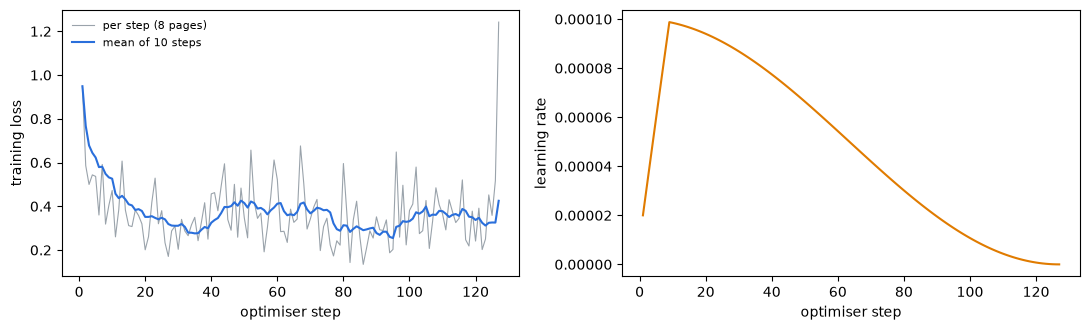

figure: training_curve.png


In [4]:
result = json.loads(RESULT.read_text())
log = pd.read_csv(LOG)
eda.show(pd.DataFrame({"before": result["val_loss_before"], "after": result["val_loss_after"]}),
         "Validation loss on the same 60 pages (lower is better):")
print(f"{result['steps']} steps over {result['train_pages']} pages in {result['minutes']} minutes")
plt = eda.plt()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4))
ax1.plot(log["step"], log["loss"], color=eda.MUTED, linewidth=0.8, label="per step (8 pages)")
ax1.plot(log["step"], log["loss"].rolling(10, min_periods=1).mean(), color=eda.INK, label="mean of 10 steps")
ax1.set_xlabel("optimiser step"); ax1.set_ylabel("training loss"); ax1.legend(frameon=False, fontsize=8)
ax2.plot(log["step"], log["lr"], color=eda.ACCENT)
ax2.set_xlabel("optimiser step"); ax2.set_ylabel("learning rate")
eda.save_figure(fig, OUT / "training_curve.png")

The training loss falls from about 0.53 to 0.40 and the validation loss falls on both kinds of page (GNHK 1.03
to 0.62, synthetic 0.28 to 0.15): the adapter learnt what it was shown. A single step can jump (each step is only
8 pages, and some pages are much harder), which is why the mean of 10 steps is drawn. Whether it learnt
something useful is the next part's question.

## Part 4. The test that decides: the development set

Lower validation loss only says the adapter fits pages like its training pages. The decision is made the same
way every reader choice was made in step 4: both readers read the 126 development images with the same settings
and the same scoring (`vision/metrics.py`). The pretrained model is pinned to the checkpoint the product uses
(`reader.PAGE_READER_REVISION`), and the adapter is checked by its SHA-256, so the comparison is between exactly
these two models.

In [5]:


def compare() -> dict:
    dev = devset.build()
    adapter_sha = hashlib.sha256((WEIGHTS / "adapter_model.safetensors").read_bytes()).hexdigest()
    models = {"base": BASE, "lora": reader.LORA_PAGE_READER}
    report = {"base_revision": reader.PAGE_READER_REVISION, "adapter_sha256": adapter_sha,
              "counts": dev.groupby("kind").size().to_dict(), "scores": {}, "pages": []}
    pages = [{"kind": r.kind, "image": Path(r.image).name, "expected": r.numbers,
              "boxes": int(r.n_boxes) if r.kind == "answersheet" else None} for r in dev.itertuples()]
    for arm, model in models.items():
        # each arm gets its own cache folder, named after the exact weights it read with
        metrics.READS = devset.DEVSETS / "paired_reads" / (reader.PAGE_READER_REVISION if arm == "base" else adapter_sha)
        read = lambda image, model=model: metrics.read_page(image, reader.VLM_GENERATE, model)  # noqa: E731
        for i, row in enumerate(dev.itertuples()):
            pages[i][arm] = metrics.numbers_read(read(row.image))
        report["scores"][arm] = {k: None if v != v else v for k, v in metrics.score(dev, lambda r: read(r.image)).items()}
        reader._vlm.cache_clear()
        gc.collect()
    for page in pages:
        if page["kind"] in ("smhd", "notebook"):
            expected = Counter(page["expected"])
            base, lora = (Counter(page[arm]) & expected for arm in models)
            page["gained"], page["lost"] = sorted((lora - base).elements()), sorted((base - lora).elements())
    report["pages"] = pages
    COMPARISON.write_text(json.dumps(report, indent=2, allow_nan=False) + "\n")
    return report


comparison = compare() if RECOMPARE else json.loads(COMPARISON.read_text())

In [6]:
scores = pd.DataFrame(comparison["scores"])
scores["change"] = scores["lora"] - scores["base"]
eda.show(scores, "Pretrained (base) against fine-tuned (lora) on the development set:")
pages = pd.DataFrame(comparison["pages"])
answersheets = pages[pages["kind"] == "answersheet"].assign(
    base=lambda d: d["base"].map(len), lora=lambda d: d["lora"].map(len))
eda.show(answersheets[["image", "boxes", "base", "lora"]].set_index("image"),
         "Question numbers found on each answer-sheet page (boxes = numbers on the page):")
eda.show(pd.Series({"answer-sheet pages where LoRA finds more": int((answersheets["lora"] > answersheets["base"]).sum()),
                    "where it finds fewer": int((answersheets["lora"] < answersheets["base"]).sum()),
                    "where it finds the same": int((answersheets["lora"] == answersheets["base"]).sum())}),
         "Page by page, on the answer sheets:")


Pretrained (base) against fine-tuned (lora) on the development set:


,base,lora,change
cer_smhd,0.072,0.067,-0.004
cer_asap,0.017,0.016,-0.001
cer_notebook,0.049,0.045,-0.004
numbers_found_smhd,0.845,0.879,0.033
numbers_found_notebook,1.000,1.000,0.000
numbers_found_answersheet,0.425,0.386,-0.039
extra_numbers_per_page,0.205,0.068,-0.136
invented_lines,12.000,10.000,-2.000



Question numbers found on each answer-sheet page (boxes = numbers on the page):


,boxes,base,lora
image,,,
32-5-1-Social-Science-Topper-Solution-_page_10_png.rf.064c0c3dcc9480a5d33f7189b0011521.jpg,2.0,1,1
32-5-1-Social-Science-Topper-Solution-_page_11_png.rf.a66be444712cc38dfe1dc1f3eb060457.jpg,5.0,1,1
32-5-1-Social-Science-Topper-Solution-_page_12_png.rf.12e6d1bc735e4e3769111fa0d496a8f2.jpg,4.0,1,1
32-5-1-Social-Science-Topper-Solution-_page_13_png.rf.0242efccd0bc4de59fbf523b68ec5078.jpg,1.0,0,0
32-5-1-Social-Science-Topper-Solution-_page_14_png.rf.577973bac58131c0bea05cf8b1288c48.jpg,3.0,1,1
32-5-1-Social-Science-Topper-Solution-_page_15_png.rf.5d1721cc9888c88ebbefcdcecc4b7ddf.jpg,2.0,1,1
32-5-1-Social-Science-Topper-Solution-_page_16_png.rf.4969885fd06fc8a8ae8451bc7b65cdfa.jpg,4.0,1,1
32-5-1-Social-Science-Topper-Solution-_page_17_png.rf.212a7ba2176512e271099cddadd822e2.jpg,4.0,1,1
32-5-1-Social-Science-Topper-Solution-_page_18_png.rf.64d8458d0bf86be4cfd96dd5a191a139.jpg,2.0,0,0



Page by page, on the answer sheets:


answer-sheet pages where LoRA finds more     1
where it finds fewer                         3
where it finds the same                     17
dtype: int64

## Conclusion, and why it leads to step 7

**The adapter reads text slightly better and invents fewer numbers**: character error falls by about half a
point on every kind of text (SMHD 7.2% to 6.7%), and the numbers read that are not on the page fall from 0.20 to
0.07 a page.

**But it does not find more question numbers on the answer sheets**, the pages closest to the exams the product
grades and the one number the fine-tuning was meant to raise. On 17 of the 21 pages both readers find the same
count; the fine-tuned reader finds more on 1 page and fewer on 3, so the mean falls from 43% to 39%. Two of those
3 pages are ones where the pretrained reader read more numbers than there are boxes, so part of its lead may be
extra numbers rather than real ones: the honest reading is **no gain**, not a clear loss. A missed number sends an
answer to the teacher however well it is spelled, and that is where the product needed the gain. The training
data explains it: GNHK notes and clean synthetic pages with EMNIST numbers are still not real answer sheets.

**Decision: the product keeps the pretrained reader**: no gain where it matters, and it is simpler to ship (no
adapter to load and check). The adapter stays in `weights/page_reader_lora/` and can
be loaded by name (`reader.LORA_PAGE_READER`). The reader is now frozen, and step 7 evaluates it, once, on the 50
Mendeley exams.